# 02 — Modeling K-Means Tingkat Bau

Input: `hasil_preprocessing.zip` dari notebook 01. K-Means (k = 3) dilatih di TS1–TS4, cluster dinamai Normal/Sedang/Tinggi, lalu diuji di TS5. Keluaran: scaler, model, dan label map (`.joblib`) untuk BE.

In [1]:
import io
import zipfile
from pathlib import Path

import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 90

K = 3
SEED = 0
LEVELS = ['Normal', 'Sedang', 'Tinggi']
REF_MINUTES = (1, 60)   # menit awal = daging masih segar
RANDOM_STATES = [0, 1, 2, 3, 4]   # untuk uji kestabilan
TARGET_SILHOUETTE = 0.50
TARGET_ARI = 0.90
FIGS = {}   # grafik yang akan disimpan

## Konfigurasi

Di Colab akan muncul tombol *Choose Files*: pilih **dua** file sekaligus, yaitu `hasil_preprocessing.zip` (dari notebook 01) dan zip dataset asli (dipakai untuk membuat scaler di bagian 10).

In [2]:
RAW_ZIP_NAME = 'e-nose dataset in uncontrolled ambient conditions (1).zip'

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def zip_has(path, member):
    with zipfile.ZipFile(path) as zf:
        return member in zf.namelist()


if IN_COLAB:
    uploaded = [Path(n) for n in files.upload() if n.lower().endswith('.zip')]
    prep = [p for p in uploaded if zip_has(p, 'dataset_train.csv')]
    raw = [p for p in uploaded if zip_has(p, 'TS1.csv')]
    if not prep or not raw:
        raise FileNotFoundError('Pilih hasil_preprocessing.zip DAN zip dataset asli, lalu jalankan sel ini lagi.')
    PREP_ZIP, RAW_ZIP = prep[0], raw[0]
else:
    PREP_ZIP = Path('hasil_preprocessing.zip')    # hasil notebook 01, di folder yang sama
    RAW_ZIP = Path('..') / RAW_ZIP_NAME           # dataset asli, satu tingkat di atas

print('Hasil preprocessing:', PREP_ZIP)
print('Dataset asli       :', RAW_ZIP)

Hasil preprocessing: hasil_preprocessing.zip
Dataset asli       : ..\e-nose dataset in uncontrolled ambient conditions (1).zip


## 1. Baca dataset hasil preprocessing

In [3]:
with zipfile.ZipFile(PREP_ZIP) as zf:
    train = pd.read_csv(zf.open('dataset_train.csv'))
    test = pd.read_csv(zf.open('dataset_test.csv'))

ID_COLS = ['series', 'minute']
LABEL_COLS = ['class', 'TVC']
fcols = [c for c in train.columns if c not in ID_COLS + LABEL_COLS]

print('train', train.shape, sorted(train['series'].unique()))
print('test ', test.shape, sorted(test['series'].unique()))
print('fitur:', fcols)

train (8640, 15) ['TS1', 'TS2', 'TS3', 'TS4']
test  (2160, 15) ['TS5']
fitur: ['lr_MQ135', 'lr_MQ136', 'lr_MQ2', 'lr_MQ3', 'lr_MQ4', 'lr_MQ5', 'lr_MQ6', 'lr_MQ8', 'lr_MQ9', 'Humidity', 'Temperature']


## 2. Fitur yang dipakai

Empat sensor yang nilainya turun searah pembusukan di semua series: MQ135, MQ3, MQ4, MQ8.

In [4]:
FEATURES = ['lr_MQ135', 'lr_MQ3', 'lr_MQ4', 'lr_MQ8']

assert set(ID_COLS + LABEL_COLS).isdisjoint(FEATURES), 'Label/penanda masuk ke fitur!'
print('Fitur:', FEATURES)

Fitur: ['lr_MQ135', 'lr_MQ3', 'lr_MQ4', 'lr_MQ8']


## 3. Aturan penamaan cluster

Ditetapkan **sebelum** clustering. Titik acuan = rerata menit 1–60 TS1–TS4 (daging segar). Centroid terdekat ke titik acuan = *Normal*, tengah = *Sedang*, terjauh = *Tinggi*. Label `class` tidak dipakai.

In [5]:
def reference_point(cols):
    mask = train['minute'].between(*REF_MINUTES)
    return train.loc[mask, cols].mean().to_numpy()


def name_clusters(km, cols):
    """Kembalikan {nomor cluster: indeks tingkat} dan jarak tiap centroid ke titik acuan."""
    dist = np.linalg.norm(km.cluster_centers_ - reference_point(cols), axis=1)
    order = np.argsort(dist)                  # dekat -> jauh
    mapping = {int(c): i for i, c in enumerate(order)}
    return mapping, dist


def fit_named(cols, seed=SEED):
    km = KMeans(n_clusters=K, n_init=10, random_state=seed).fit(train[cols].to_numpy())
    mapping, dist = name_clusters(km, cols)
    level_train = np.vectorize(mapping.get)(km.labels_)
    return km, mapping, dist, level_train


def predict_level(km, mapping, df, cols):
    return np.vectorize(mapping.get)(km.predict(df[cols].to_numpy()))

## 4. Memilih jumlah cluster (k)

Elbow dan silhouette untuk k = 2–6 di data train, sebagai bahan diskusi apakah k = 3 masuk akal.

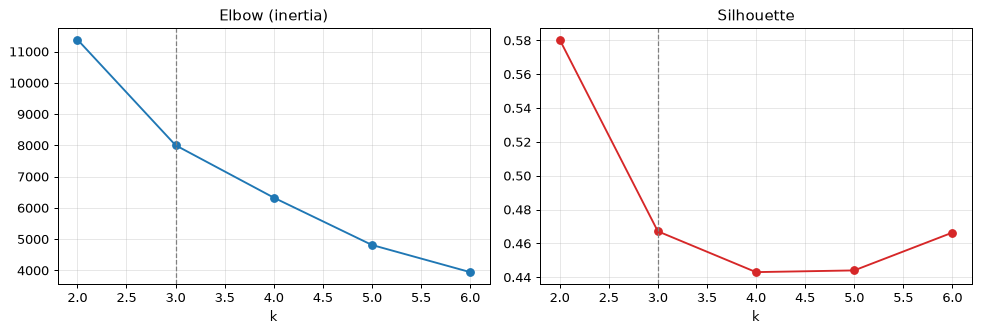

,inertia,silhouette
k,,
2,11386.698,0.581
3,8005.094,0.467
4,6329.219,0.443
5,4815.053,0.444
6,3946.472,0.466


In [6]:
X = train[FEATURES].to_numpy()
rows = []
for k in range(2, 7):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    rows.append({'k': k, 'inertia': km_k.inertia_,
                 'silhouette': silhouette_score(X, km_k.labels_)})
k_scan = pd.DataFrame(rows).set_index('k')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(k_scan.index, k_scan['inertia'], marker='o')
axes[1].plot(k_scan.index, k_scan['silhouette'], marker='o', color='tab:red')
for ax, title in zip(axes, ['Elbow (inertia)', 'Silhouette']):
    ax.axvline(K, color='grey', ls='--', lw=1)
    ax.set_xlabel('k'); ax.set_title(title); ax.grid(alpha=.3)
plt.tight_layout(); FIGS['01_elbow_silhouette_k2-6.png'] = fig; plt.show()

k_scan.round(3)

**Interpretasi:** Inertia turun bertahap tanpa "siku" yang tajam. Silhouette tertinggi di k = 2 (0,58), karena data paling mudah dibelah menjadi "segar" dan "busuk". Di k = 3 silhouette 0,47, dan k = 4–6 tidak lebih baik (0,44–0,47). Jadi k = 3 wajar dipakai untuk tiga tingkat bau, dengan konsekuensi batas tingkat *Sedang* tidak setajam pemisahan dua kelompok.

## 5. Model final

In [7]:
km, mapping, dist, train['level'] = fit_named(FEATURES)

centroids = pd.DataFrame(km.cluster_centers_, columns=FEATURES)
centroids['jarak_ke_acuan'] = dist
centroids['tingkat'] = [LEVELS[mapping[c]] for c in range(K)]
centroids['jumlah_train'] = pd.Series(km.labels_).value_counts().sort_index().to_numpy()
centroids.sort_values('jarak_ke_acuan').round(3)

,lr_MQ135,lr_MQ3,lr_MQ4,lr_MQ8,jarak_ke_acuan,tingkat,jumlah_train
0,1.307,1.432,1.175,1.322,0.964,Normal,2313
2,-0.058,0.011,0.590,-0.076,3.348,Sedang,1975
1,-0.669,-0.766,-0.893,-0.668,5.027,Tinggi,4352


## 6. Evaluasi clustering (TC-23)

### Kestabilan: 5 random state

K-Means dijalankan dengan 5 random state berbeda, lalu ARI dihitung untuk setiap pasangan. ARI = 1 berarti hasilnya identik.

In [8]:
runs = {rs: fit_named(FEATURES, seed=rs)[3] for rs in RANDOM_STATES}
ari_matrix = pd.DataFrame(
    [[adjusted_rand_score(runs[a], runs[b]) for b in RANDOM_STATES] for a in RANDOM_STATES],
    index=[f'rs={r}' for r in RANDOM_STATES], columns=[f'rs={r}' for r in RANDOM_STATES])
pairs = ari_matrix.to_numpy()[np.triu_indices(len(RANDOM_STATES), k=1)]
print(f'ARI antar-random state: min {pairs.min():.3f} | rerata {pairs.mean():.3f}')
ari_matrix.round(3)

ARI antar-random state: min 0.995 | rerata 0.998


,rs=0,rs=1,rs=2,rs=3,rs=4
rs=0,1.000,0.995,1.000,1.000,1.000
rs=1,0.995,1.000,0.995,0.995,0.995
rs=2,1.000,0.995,1.000,1.000,1.000
rs=3,1.000,0.995,1.000,1.000,1.000
rs=4,1.000,0.995,1.000,1.000,1.000


### Ringkasan untuk Lampiran G

In [9]:
Xtr = train[FEATURES].to_numpy()
sil = silhouette_score(Xtr, train['level'])
dbi = davies_bouldin_score(Xtr, train['level'])

tc23 = pd.DataFrame([
    {'metrik': 'Silhouette (TS1-TS4, k=3)', 'nilai': sil, 'target': f'>= {TARGET_SILHOUETTE}',
     'status': 'Tercapai' if sil >= TARGET_SILHOUETTE else 'Belum tercapai'},
    {'metrik': 'Davies-Bouldin (TS1-TS4, k=3)', 'nilai': dbi, 'target': 'pembanding (makin kecil makin baik)', 'status': '-'},
    {'metrik': 'ARI antar-random state (min, 5 run)', 'nilai': pairs.min(), 'target': f'>= {TARGET_ARI}',
     'status': 'Tercapai' if pairs.min() >= TARGET_ARI else 'Belum tercapai'},
]).set_index('metrik')
tc23.round(3)

,nilai,target,status
metrik,,,
"Silhouette (TS1-TS4, k=3)",0.467,>= 0.5,Belum tercapai
"Davies-Bouldin (TS1-TS4, k=3)",0.926,pembanding (makin kecil makin baik),-
"ARI antar-random state (min, 5 run)",0.995,>= 0.9,Tercapai


**Interpretasi:** Hasil K-Means sangat stabil: kelima random state memberi pembagian yang hampir identik (ARI minimal 0,99, jauh di atas target 0,90), jadi hasilnya tidak bergantung pada titik awal acak. Silhouette 0,47 belum mencapai target 0,50. Artinya cluster cukup terpisah, tetapi batas antar-tingkat, terutama di sekitar *Sedang*, tidak tajam: data bergerak bertahap dari segar ke busuk, sehingga ada titik di perbatasan dua tingkat. Davies-Bouldin 0,93 (di bawah 1) mendukung bahwa cluster masih lebih rapat di dalam daripada jaraknya ke cluster lain. Pembanding k = 2–6 di bagian 4 menunjukkan silhouette tertinggi di k = 2 (0,58); k = 3 tetap dipakai karena sistem membutuhkan tiga tingkat bau.

## 7. Evaluasi di data train (TS1–TS4)

In [10]:
lvl_name = lambda s: pd.Categorical(np.array(LEVELS)[s], categories=LEVELS)
class_order = ['excellent', 'good', 'acceptable', 'spoiled']

print('Tingkat vs class:')
display(pd.crosstab(pd.Categorical(train['class'], class_order), lvl_name(train['level']),
                    rownames=['class'], colnames=['tingkat']))
print('Tingkat vs series:')
display(pd.crosstab(train['series'], lvl_name(train['level']), colnames=['tingkat']))
train.groupby(lvl_name(train['level']), observed=True)['TVC'].describe().round(2)

Tingkat vs class:


tingkat,Normal,Sedang,Tinggi
class,,,
excellent,1320,0,0
good,993,1248,39
acceptable,0,605,1075
spoiled,0,122,3238


Tingkat vs series:


tingkat,Normal,Sedang,Tinggi
series,,,
TS1,720,223,1217
TS2,569,913,678
TS3,484,377,1299
TS4,540,462,1158


,count,mean,std,min,25%,50%,75%,max
Normal,2313.0,2.95,0.39,2.23,2.62,2.97,3.29,3.67
Sedang,1975.0,4.07,0.63,3.28,3.58,3.69,4.85,4.99
Tinggi,4352.0,4.95,0.14,3.69,4.91,4.96,5.03,5.10


## 8. Evaluasi di data uji (TS5)

TS5 tidak pernah dipakai untuk melatih atau memilih model.

In [11]:
test['level'] = predict_level(km, mapping, test, FEATURES)

print('Tingkat vs class (TS5):')
display(pd.crosstab(pd.Categorical(test['class'], class_order), lvl_name(test['level']),
                    rownames=['class'], colnames=['tingkat']))

Xt = test[FEATURES].to_numpy()
metrics = pd.DataFrame({
    'train (TS1-TS4)': {
        'silhouette': silhouette_score(train[FEATURES], train['level']),
        'davies_bouldin': davies_bouldin_score(train[FEATURES], train['level']),
        'ARI_class': adjusted_rand_score(train['class'], train['level']),
        'spearman_TVC': spearmanr(train['level'], train['TVC'])[0],
    },
    'test (TS5)': {
        'silhouette': silhouette_score(Xt, test['level']),
        'davies_bouldin': davies_bouldin_score(Xt, test['level']),
        'ARI_class': adjusted_rand_score(test['class'], test['level']),
        'spearman_TVC': spearmanr(test['level'], test['TVC'])[0],
    },
})
metrics.round(3)

Tingkat vs class (TS5):


tingkat,Normal,Sedang,Tinggi
class,,,
excellent,360,0,0
good,129,411,0
acceptable,0,420,0
spoiled,0,287,553


,train (TS1-TS4),test (TS5)
silhouette,0.467,0.631
davies_bouldin,0.926,0.433
ARI_class,0.501,0.361
spearman_TVC,0.871,0.704


In [12]:
test.groupby(lvl_name(test['level']), observed=True)['TVC'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Normal,489.0,2.79,0.31,2.31,2.59,2.84,3.06,3.35
Sedang,1118.0,4.43,0.68,3.29,3.62,4.88,5.00,5.04
Tinggi,553.0,4.95,0.05,4.89,4.92,4.94,4.99,5.04


## 9. Tren tingkat bau terhadap waktu

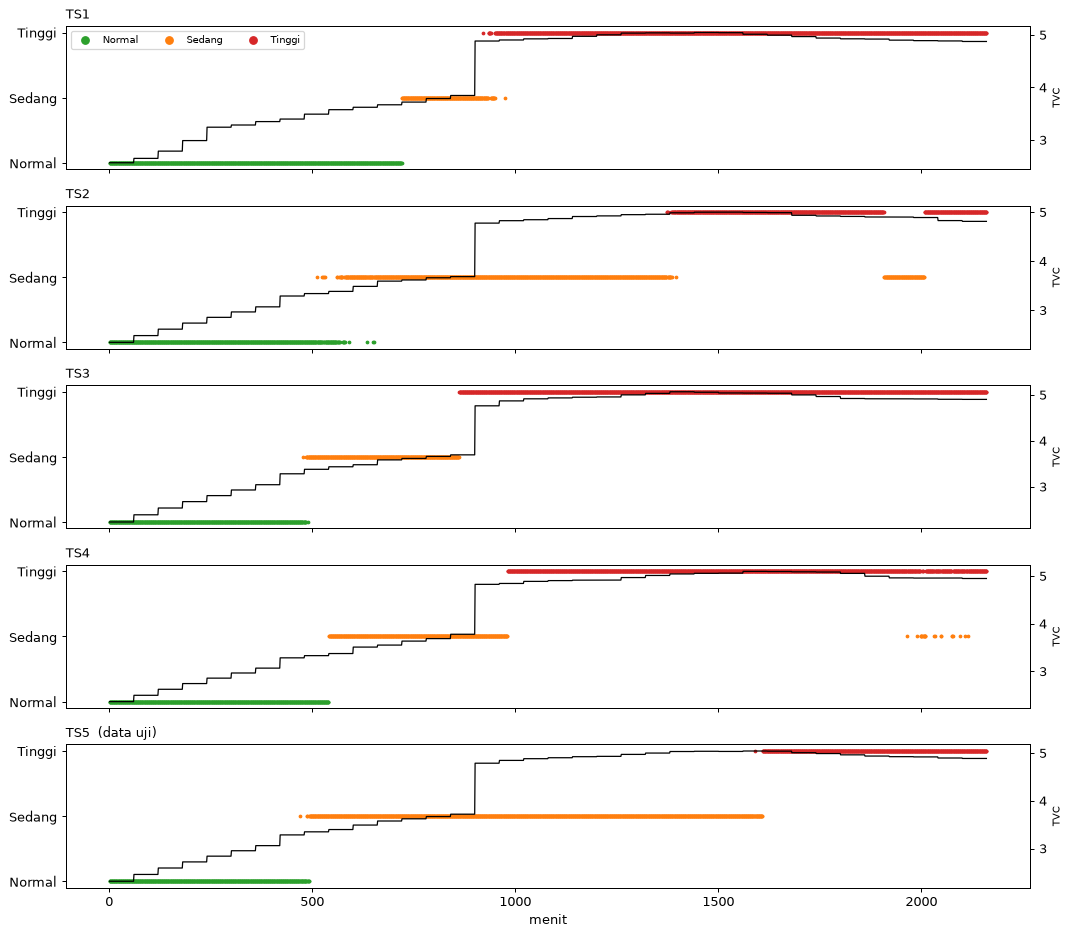

In [13]:
allp = pd.concat([train, test], ignore_index=True)
series_list = sorted(allp['series'].unique())
colors = ['tab:green', 'tab:orange', 'tab:red']

fig, axes = plt.subplots(len(series_list), 1, figsize=(12, 2.1 * len(series_list)), sharex=True)
for ax, s in zip(axes, series_list):
    g = allp[allp['series'] == s]
    for i, lv in enumerate(LEVELS):
        m = g['level'] == i
        ax.scatter(g.loc[m, 'minute'], np.full(m.sum(), i), s=4, color=colors[i], label=lv)
    ax.set_yticks(range(K)); ax.set_yticklabels(LEVELS)
    ax2 = ax.twinx()
    ax2.plot(g['minute'], g['TVC'], color='black', lw=1)
    ax2.set_ylabel('TVC', fontsize=8)
    ax.set_title(f'{s}' + ('  (data uji)' if s == 'TS5' else ''), fontsize=10, loc='left')
axes[-1].set_xlabel('menit')
axes[0].legend(loc='upper left', ncol=3, fontsize=8, markerscale=3)
plt.tight_layout(); FIGS['02_tren_tingkat_bau_per_series.png'] = fig; plt.show()

**Interpretasi:** Di kelima series, tingkat bau bergerak searah waktu: *Normal* di awal, *Sedang* di tengah, lalu *Tinggi* setelah TVC melonjak ke sekitar 5. Pada TS1, TS3, dan TS4 perpindahan ke *Tinggi* hampir tepat di lonjakan TVC (sekitar menit 900–1000). Pada TS2 dan TS5 (data uji), tingkat *Tinggi* baru muncul sekitar menit 1.400–1.600, jadi model terlambat sekitar 500–700 menit; selama itu bau masih dinilai *Sedang* padahal TVC sudah tinggi. TS2 juga sempat turun lagi ke *Sedang* di sekitar menit 1.900–2.000. Untuk SMART-TPS, ini berarti tingkat *Tinggi* cenderung muncul belakangan, bukan sebagai peringatan dini.

## 10. Validasi TS5 (TC-24)

Kriteria Tabel 6.3: tingkat bau di TS5 **berkorelasi positif dengan TVC**, dan tingkat **Tinggi paling banyak muncul pada data berlabel kualitas terburuk** (`spoiled`).

In [14]:
WORST = 'spoiled'
spoiled = test['class'] == WORST
is_tinggi = test['level'] == LEVELS.index('Tinggi')

# Sebaran tingkat bau pada data spoiled (dalam persen)
dist_spoiled = (pd.Series(lvl_name(test.loc[spoiled, 'level'])).value_counts(normalize=True)
                .reindex(LEVELS) * 100)
print(f'Sebaran tingkat bau pada data {WORST} (TS5):')
print((dist_spoiled.round(1).astype(str) + ' %').to_string())

pct_tinggi_in_spoiled = dist_spoiled['Tinggi']
pct_spoiled_in_tinggi = (spoiled & is_tinggi).sum() / is_tinggi.sum() * 100
print()
print(f'Tinggi pada data {WORST}       : {pct_tinggi_in_spoiled:.1f} %')
print(f'Data {WORST} di antara Tinggi  : {pct_spoiled_in_tinggi:.1f} %')

Sebaran tingkat bau pada data spoiled (TS5):
Normal     0.0 %
Sedang    34.2 %
Tinggi    65.8 %

Tinggi pada data spoiled       : 65.8 %
Data spoiled di antara Tinggi  : 100.0 %


In [15]:
rho_tvc = spearmanr(test['level'], test['TVC'])[0]
top_level = dist_spoiled.idxmax()

tc24 = pd.DataFrame([
    {'kriteria': 'Korelasi tingkat bau vs TVC positif', 'hasil': f'Spearman = {rho_tvc:.3f}',
     'status': 'Lulus' if rho_tvc > 0 else 'Tidak lulus'},
    {'kriteria': f'Tinggi paling banyak pada data {WORST}', 'hasil': f'{top_level} terbanyak ({dist_spoiled.max():.1f} %)',
     'status': 'Lulus' if top_level == 'Tinggi' else 'Tidak lulus'},
]).set_index('kriteria')
tc24

,hasil,status
kriteria,,
Korelasi tingkat bau vs TVC positif,Spearman = 0.704,Lulus
Tinggi paling banyak pada data spoiled,Tinggi terbanyak (65.8 %),Lulus


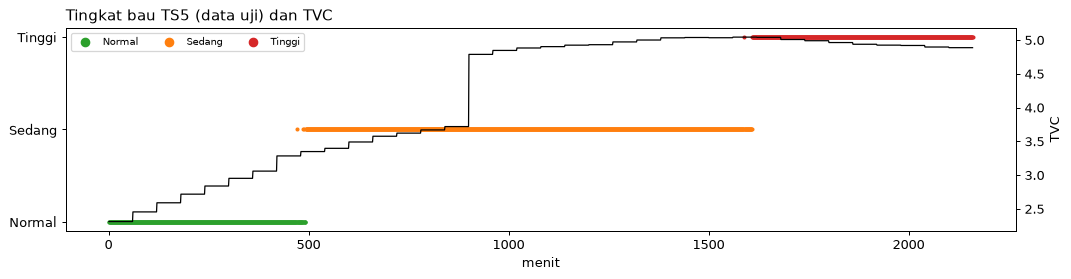

In [16]:
g = test.sort_values('minute')
fig, ax = plt.subplots(figsize=(12, 3.2))
for i, lv in enumerate(LEVELS):
    m = g['level'] == i
    ax.scatter(g.loc[m, 'minute'], np.full(m.sum(), i), s=5, color=colors[i], label=lv)
ax.set_yticks(range(K)); ax.set_yticklabels(LEVELS); ax.set_xlabel('menit')
ax2 = ax.twinx()
ax2.plot(g['minute'], g['TVC'], color='black', lw=1, label='TVC')
ax2.set_ylabel('TVC')
ax.set_title('Tingkat bau TS5 (data uji) dan TVC', loc='left')
ax.legend(loc='upper left', ncol=3, fontsize=8, markerscale=3)
plt.tight_layout(); FIGS['03_tingkat_bau_TS5.png'] = fig; plt.show()

**Interpretasi:** Kedua kriteria TC-24 terpenuhi. Korelasi Spearman tingkat bau dengan TVC 0,70 (positif): makin banyak bakteri, makin tinggi tingkat baunya. Pada data *spoiled*, 65,8% dinilai *Tinggi*, 34,2% *Sedang*, dan tidak ada yang *Normal*; sebaliknya, seluruh data *Tinggi* (100%) berasal dari data *spoiled*, jadi tidak ada peringatan *Tinggi* yang salah. Grafik menunjukkan urutan Normal → Sedang → Tinggi sesuai kenaikan TVC. Kelemahannya, TVC sudah melonjak ke sekitar 4,8 di menit ±900, tetapi tingkat *Tinggi* baru muncul di menit ±1.600; 34,2% data *spoiled* yang dinilai *Sedang* berasal dari rentang ini.

## 11. Ringkasan

In [17]:
print('Fitur          :', FEATURES)
print('k              :', K)
print('Penamaan       : jarak centroid ke rerata menit', REF_MINUTES, 'TS1-TS4')
print(metrics.round(3).to_string())

Fitur          : ['lr_MQ135', 'lr_MQ3', 'lr_MQ4', 'lr_MQ8']
k              : 3
Penamaan       : jarak centroid ke rerata menit (1, 60) TS1-TS4
                train (TS1-TS4)  test (TS5)
silhouette                0.467       0.631
davies_bouldin            0.926       0.433
ARI_class                 0.501       0.361
spearman_TVC              0.871       0.704


## 12. Simpan scaler, model, dan label map

Tiga file `.joblib` dikemas dalam `model_kmeans.zip`, lalu otomatis terunduh di Colab:

| File | Isi |
|---|---|
| `scaler.joblib` | StandardScaler 4 fitur terpilih, dibuat ulang dari dataset asli TS1–TS4 |
| `kmeans_model.joblib` | Model K-Means k = 3 |
| `label_map.joblib` | Nomor cluster → Normal/Sedang/Tinggi |

Input untuk BE: `ln(Rs/R0)` keempat sensor, urut sesuai `scaler.feature_names_in_`.

In [18]:
from sklearn.preprocessing import StandardScaler

# Scaler dibuat ulang dari dataset asli dengan langkah yang sama seperti notebook 01:
# nilai sensor / median menit 1-60 series-nya, lalu ln, lalu StandardScaler di TS1-TS4
sensors = [f.replace('lr_', '') for f in FEATURES]
frames = []
with zipfile.ZipFile(RAW_ZIP) as zf:
    for s_name in sorted(train['series'].unique()):
        d = pd.read_csv(zf.open(f'{s_name}.csv'))
        base = d.loc[d['minute'].between(*REF_MINUTES), sensors].median()
        lr = np.log(d[sensors] / base).add_prefix('lr_')
        frames.append(pd.concat([d[['minute']].assign(series=s_name), lr], axis=1))
lr_train = pd.concat(frames, ignore_index=True)

scaler = StandardScaler().fit(lr_train[FEATURES])

# Cek: hasil standarisasi harus sama dengan dataset_train dari notebook 01
check = lr_train.merge(train[['series', 'minute'] + FEATURES], on=['series', 'minute'], suffixes=('', '_nb01'))
z = scaler.transform(check[FEATURES])
assert len(check) == len(train) and np.allclose(z, check[[f + '_nb01' for f in FEATURES]].to_numpy())
print('Scaler cocok dengan hasil notebook 01')
print(pd.DataFrame({'mean': scaler.mean_, 'std': scaler.scale_}, index=FEATURES).round(4))

label_map = {int(c): LEVELS[mapping[c]] for c in range(K)}
print('label_map:', label_map)

out_zip = Path('model_kmeans.zip')
with zipfile.ZipFile(out_zip, 'w', zipfile.ZIP_DEFLATED) as zf:
    for name, obj in [('scaler.joblib', scaler), ('kmeans_model.joblib', km), ('label_map.joblib', label_map)]:
        buf = io.BytesIO()
        joblib.dump(obj, buf)
        zf.writestr(name, buf.getvalue())
print('Tersimpan:', out_zip, zipfile.ZipFile(out_zip).namelist())

if IN_COLAB:
    files.download(str(out_zip))

Scaler cocok dengan hasil notebook 01
            mean     std
lr_MQ135 -1.0063  0.5259
lr_MQ3   -0.7737  0.4593
lr_MQ4   -2.3152  1.3307
lr_MQ8   -1.7340  1.0742
label_map: {0: 'Normal', 1: 'Tinggi', 2: 'Sedang'}
Tersimpan: model_kmeans.zip ['scaler.joblib', 'kmeans_model.joblib', 'label_map.joblib']


### Cek ulang: prediksi dengan file `.joblib`

Meniru cara BE memakai file: mulai dari nilai `ln(Rs/R0)` (sebelum standarisasi), lalu scaler → model → label map.

In [19]:
with zipfile.ZipFile(out_zip) as zf:
    sc = joblib.load(io.BytesIO(zf.read('scaler.joblib')))
    model = joblib.load(io.BytesIO(zf.read('kmeans_model.joblib')))
    lmap = joblib.load(io.BytesIO(zf.read('label_map.joblib')))

raw = pd.DataFrame(test[FEATURES].to_numpy() * sc.scale_ + sc.mean_, columns=FEATURES)   # kembali ke ln(Rs/R0)
pred = [lmap[c] for c in model.predict(sc.transform(raw))]

same = (np.array(pred) == np.array(LEVELS)[test['level']]).mean()
print(f'Prediksi dari file .joblib sama dengan notebook: {same:.1%}')
assert same == 1.0

Prediksi dari file .joblib sama dengan notebook: 100.0%


## 13. Simpan grafik hasil

Semua grafik disimpan sebagai PNG di `grafik_hasil.zip`. Di Colab, browser mungkin meminta izin karena ada dua file yang diunduh.

In [20]:
fig_zip = Path('grafik_hasil.zip')
with zipfile.ZipFile(fig_zip, 'w', zipfile.ZIP_DEFLATED) as zf:
    for name, f in FIGS.items():
        buf = io.BytesIO()
        f.savefig(buf, format='png', dpi=150, bbox_inches='tight')
        zf.writestr(name, buf.getvalue())
print('Tersimpan:', fig_zip, zipfile.ZipFile(fig_zip).namelist())

if IN_COLAB:
    files.download(str(fig_zip))

Tersimpan: grafik_hasil.zip ['01_elbow_silhouette_k2-6.png', '02_tren_tingkat_bau_per_series.png', '03_tingkat_bau_TS5.png']
